# Big Data - Australia Rain Prediction

Nom : Felipe Mateus FALCÃO BARRETO

Date : 12 novembre 2026

L'objectif du projet est de développer un modèle de Machine Learning capable de prédire s'il pleuvra un jour donné, en utilisant comme variables d'entrée les données météorologiques enregistrées la veille.

En termes de classification binaire :

- 1 : Il pleuvra le lendemain.

- 0 : Il ne pleuvra pas le lendemain.

Inspiré du code :

Baneerjee, Prashant. [Logistic Regression Classifier Tutorial](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588).

Certaines techniques qui ont été implémentées ne provenaient pas de la base de code.

Le notebook s’exécute de bout en bout.

### Libs

In [ ]:
import matplotlib.pyplot as plt
import os
from pyspark.ml import Pipeline
from pyspark.ml.feature import (Imputer, StringIndexer, OneHotEncoder, VectorAssembler, MinMaxScaler)
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, when, round, to_date, year, month, dayofweek, avg, dayofmonth, lit, sin, cos, create_map, radians
from pyspark.ml.classification import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
import pandas as pd
from sklearn.metrics import roc_curve
from math import pi
from itertools import chain
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics

## Data

### Java and PySpark configuration

In [95]:
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

spark = SparkSession.builder.appName("RainAustralia").master("local[*]").config("spark.driver.memory", "4g").config("spark.ui.showConsoleProgress", "false").getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print(spark.version)

3.5.7


### Data importation

In [96]:
df = spark.read.csv("hdfs://localhost:8020/rain/input/weatherAUS.csv", header=True, inferSchema=True, nullValue='NA')
print("Total records:", df.count())
df.show(5)

Total records: 145460
+----------+--------+-------+-------+--------+-----------+--------+-----------+-------------+----------+----------+------------+------------+-----------+-----------+-----------+-----------+--------+--------+-------+-------+---------+------------+
|      Date|Location|MinTemp|MaxTemp|Rainfall|Evaporation|Sunshine|WindGustDir|WindGustSpeed|WindDir9am|WindDir3pm|WindSpeed9am|WindSpeed3pm|Humidity9am|Humidity3pm|Pressure9am|Pressure3pm|Cloud9am|Cloud3pm|Temp9am|Temp3pm|RainToday|RainTomorrow|
+----------+--------+-------+-------+--------+-----------+--------+-----------+-------------+----------+----------+------------+------------+-----------+-----------+-----------+-----------+--------+--------+-------+-------+---------+------------+
|2008-12-01|  Albury|   13.4|   22.9|     0.6|       NULL|    NULL|          W|           44|         W|       WNW|          20|          24|         71|         22|     1007.7|     1007.1|       8|    NULL|   16.9|   21.8|       No|    

## Exploratory Data Analysis - EDA

In [97]:
col_names = df.columns
print(f"Dataset shape: {df.count()}, {len(df.columns)}\nColumns: {col_names}\nSchema:")
df.printSchema()

Dataset shape: 145460, 23
Columns: ['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']
Schema:
root
 |-- Date: date (nullable = true)
 |-- Location: string (nullable = true)
 |-- MinTemp: double (nullable = true)
 |-- MaxTemp: double (nullable = true)
 |-- Rainfall: double (nullable = true)
 |-- Evaporation: double (nullable = true)
 |-- Sunshine: double (nullable = true)
 |-- WindGustDir: string (nullable = true)
 |-- WindGustSpeed: integer (nullable = true)
 |-- WindDir9am: string (nullable = true)
 |-- WindDir3pm: string (nullable = true)
 |-- WindSpeed9am: integer (nullable = true)
 |-- WindSpeed3pm: integer (nullable = true)
 |-- Humidity9am: integer (nullable = true)
 |-- Humidity3pm: integer (nullable = true)
 |-- Pressure9am:

### Missing data

In [98]:
missing_values = df.select([sum(when(col(c).isNull(), 1).otherwise(0)).alias(c) for c in df.columns])
missing_values.show(vertical=True)


-RECORD 0--------------
 Date          | 0     
 Location      | 0     
 MinTemp       | 1485  
 MaxTemp       | 1261  
 Rainfall      | 3261  
 Evaporation   | 62790 
 Sunshine      | 69835 
 WindGustDir   | 10326 
 WindGustSpeed | 10263 
 WindDir9am    | 10566 
 WindDir3pm    | 4228  
 WindSpeed9am  | 1767  
 WindSpeed3pm  | 3062  
 Humidity9am   | 2654  
 Humidity3pm   | 4507  
 Pressure9am   | 15065 
 Pressure3pm   | 15028 
 Cloud9am      | 55888 
 Cloud3pm      | 59358 
 Temp9am       | 1767  
 Temp3pm       | 3609  
 RainToday     | 3261  
 RainTomorrow  | 3267  



### Target distribution

In [99]:
total = df.count()
df.groupBy("RainTomorrow").count().withColumn("Percentage", round(col("count") / total * 100, 2)).show()


+------------+------+----------+
|RainTomorrow| count|Percentage|
+------------+------+----------+
|        NULL|  3267|      2.25|
|          No|110316|     75.84|
|         Yes| 31877|     21.91|
+------------+------+----------+



### Categorical and numerical columns

In [100]:
categorical = [c for c, dtype in df.dtypes if dtype == "string" and c != "RainTomorrow"]
print(f'There are {len(categorical)} categorical variables\nThe categorical variables are: {categorical}')

df.select(categorical).show(5)

There are 5 categorical variables
The categorical variables are: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
+--------+-----------+----------+----------+---------+
|Location|WindGustDir|WindDir9am|WindDir3pm|RainToday|
+--------+-----------+----------+----------+---------+
|  Albury|          W|         W|       WNW|       No|
|  Albury|        WNW|       NNW|       WSW|       No|
|  Albury|        WSW|         W|       WSW|       No|
|  Albury|         NE|        SE|         E|       No|
|  Albury|          W|       ENE|        NW|       No|
+--------+-----------+----------+----------+---------+
only showing top 5 rows



In [101]:
numerical = [c for c, dtype in df.dtypes if dtype in ("int", "bigint", "float", "double")]
print(f'There are {len(numerical)} numerical variables\nThe numerical variables are: {numerical}')

df.select(numerical).show(5)

There are 16 numerical variables
The numerical variables are: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
+-------+-------+--------+-----------+--------+-------------+------------+------------+-----------+-----------+-----------+-----------+--------+--------+-------+-------+
|MinTemp|MaxTemp|Rainfall|Evaporation|Sunshine|WindGustSpeed|WindSpeed9am|WindSpeed3pm|Humidity9am|Humidity3pm|Pressure9am|Pressure3pm|Cloud9am|Cloud3pm|Temp9am|Temp3pm|
+-------+-------+--------+-----------+--------+-------------+------------+------------+-----------+-----------+-----------+-----------+--------+--------+-------+-------+
|   13.4|   22.9|     0.6|       NULL|    NULL|           44|          20|          24|         71|         22|     1007.7|     1007.1|       8|    NULL|   16.9|   21.8|
|    7.4|   25.1|     0.0|       NULL|   

### Dataset resume by data type

In [102]:
# Categorical variable analysis
for c in categorical:
    print(f"\n{c}:")
    df.groupBy(c).count().orderBy(col("count").desc()).show()


Location:
+------------+-----+
|    Location|count|
+------------+-----+
|    Canberra| 3436|
|      Sydney| 3344|
|    Brisbane| 3193|
|      Hobart| 3193|
|   Melbourne| 3193|
|    Adelaide| 3193|
|       Perth| 3193|
|      Darwin| 3193|
|  Wollongong| 3040|
|      Albury| 3040|
|     Bendigo| 3040|
|    Ballarat| 3040|
| MountGinini| 3040|
|      Cairns| 3040|
|      Albany| 3040|
|   GoldCoast| 3040|
|MountGambier| 3040|
|  Townsville| 3040|
|AliceSprings| 3040|
|  Launceston| 3040|
+------------+-----+
only showing top 20 rows


WindGustDir:
+-----------+-----+
|WindGustDir|count|
+-----------+-----+
|       NULL|10326|
|          W| 9915|
|         SE| 9418|
|          N| 9313|
|        SSE| 9216|
|          E| 9181|
|          S| 9168|
|        WSW| 9069|
|         SW| 8967|
|        SSW| 8736|
|        WNW| 8252|
|         NW| 8122|
|        ENE| 8104|
|        ESE| 7372|
|         NE| 7133|
|        NNW| 6620|
|        NNE| 6548|
+-----------+-----+


WindDir9am:
+----------

In [103]:
# Numerical variable analysis
df.select(numerical).describe().show()

+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+------------------+------------------+-----------------+------------------+-----------------+------------------+------------------+------------------+------------------+
|summary|           MinTemp|           MaxTemp|         Rainfall|      Evaporation|          Sunshine|     WindGustSpeed|      WindSpeed9am|      WindSpeed3pm|       Humidity9am|      Humidity3pm|       Pressure9am|      Pressure3pm|          Cloud9am|          Cloud3pm|           Temp9am|           Temp3pm|
+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+------------------+------------------+-----------------+------------------+-----------------+------------------+------------------+------------------+------------------+
|  count|            143975|            144199|           142199|     

### Distribution of the target data

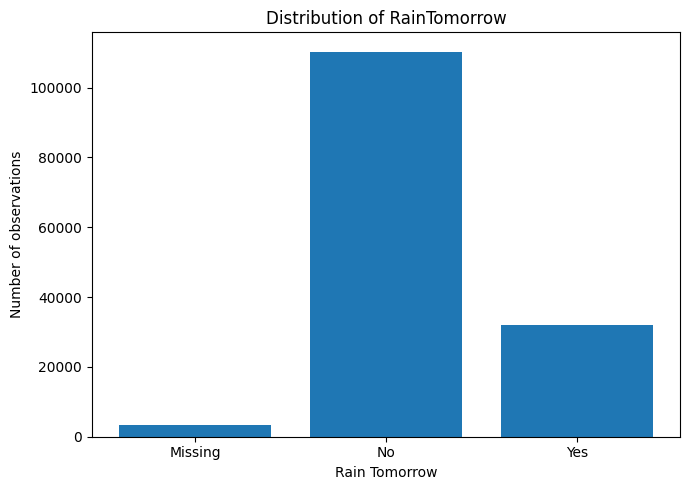

In [104]:
target_counts = df.groupBy("RainTomorrow").count().toPandas()

# Replace null category with "Missing"
target_counts["RainTomorrow"] = target_counts["RainTomorrow"].fillna("Missing")

plt.figure(figsize=(7, 5))
plt.bar(target_counts["RainTomorrow"], target_counts["count"])
plt.title("Distribution of RainTomorrow")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

On observe une prédominance de jours sans pluie nettement supérieure à toute autre donnée, ce qui peut influencer le résultat de la prévision.

### Top 10 locations with highest rain probability

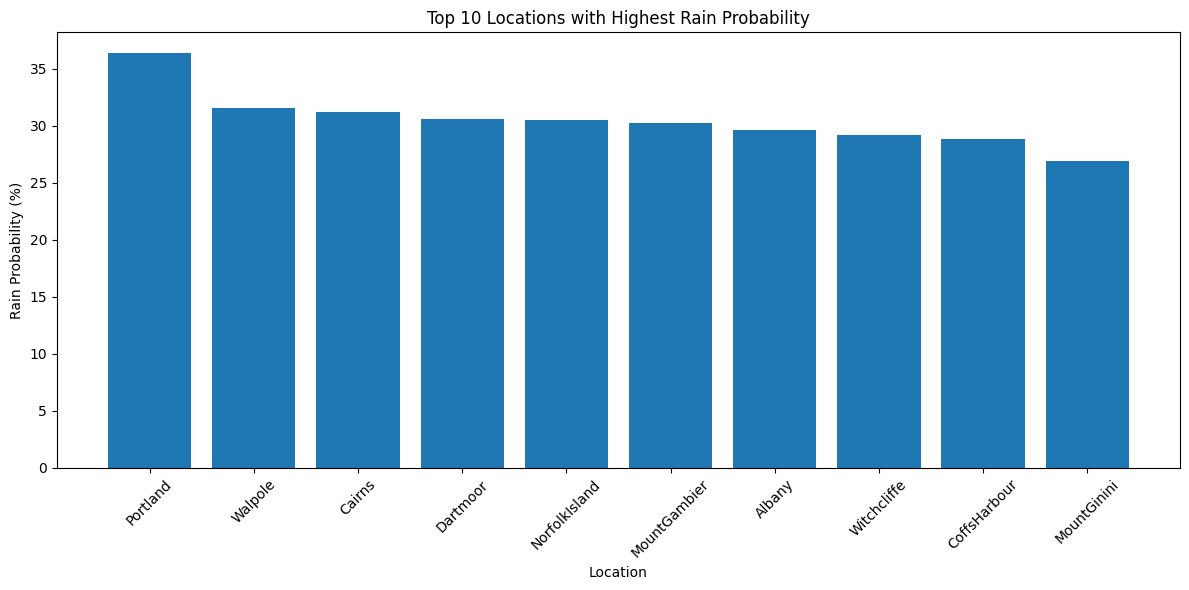

In [105]:
location_rain = df.groupBy("Location").agg((avg(when(col("RainTomorrow") == "Yes", 1).otherwise(0)) * 100).alias("Rain_Percentage")).orderBy("Rain_Percentage", ascending=False).toPandas()


plt.figure(figsize=(12, 6))
plt.bar(location_rain["Location"].head(10), location_rain["Rain_Percentage"].head(10))
plt.title("Top 10 Locations with Highest Rain Probability")
plt.xlabel("Location")
plt.ylabel("Rain Probability (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Certaines villes peuvent influencer les prévisions du modèle. C'est le cas, par exemple, de Portland, qui a connu beaucoup plus de pluie que les autres villes.

### Target variable Vs numerical data at 9am

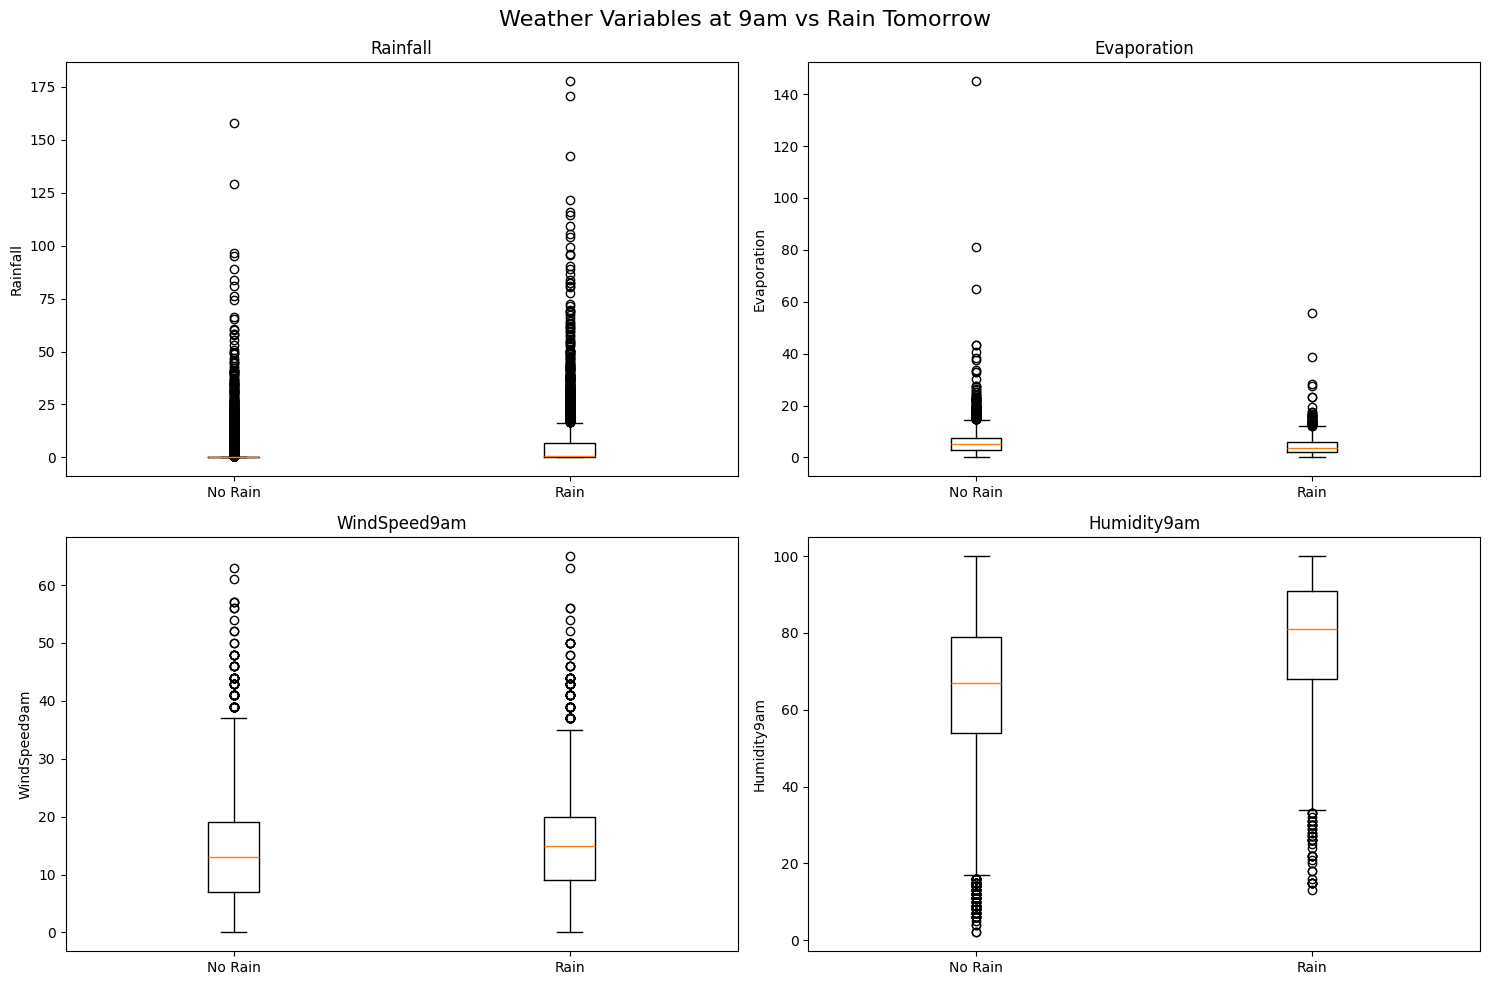

In [106]:
sample = df.select("Rainfall", "Evaporation", "WindSpeed9am","Humidity9am", "RainTomorrow").sample(False, 0.1, seed=42).toPandas()
columns = ["Rainfall", "Evaporation", "WindSpeed9am", "Humidity9am"]
plt.figure(figsize=(15, 10))


for i, column in enumerate(columns, 1):
    plt.subplot(2, 2, i)
    groups = [sample[sample["RainTomorrow"] == "No"][column].dropna(), sample[sample["RainTomorrow"] == "Yes"][column].dropna()]
    plt.boxplot(groups, tick_labels=["No Rain", "Rain"])
    plt.title(column)
    plt.ylabel(column)

plt.suptitle("Weather Variables at 9am vs Rain Tomorrow", fontsize=16)
plt.tight_layout()
plt.show()

On observe une grande quantité de valeurs aberrantes (outliers), susceptibles d'affecter l'entraînement du modèle.

### Humidity vs Temperature

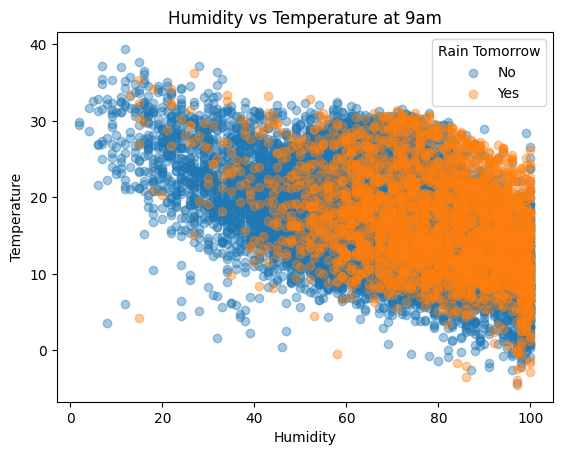

In [108]:
sample = df.select("Humidity9am", "Temp9am", "RainTomorrow").sample(False, 0.1, seed=42).toPandas()


for label, group in sample.groupby("RainTomorrow"):
    if pd.notna(label):
        plt.scatter(group["Humidity9am"], group["Temp9am"], label=label, alpha=0.4)

plt.title("Humidity vs Temperature at 9am")
plt.xlabel("Humidity")
plt.ylabel("Temperature")
plt.legend(title="Rain Tomorrow")
plt.show()

On remarque que certaines variables peuvent présenter une tendance à distinguer les résultats. Par exemple, l'humidité est généralement plus élevée la veille des jours de pluie que la veille des jours sans pluie.

### Correlation Heatmap

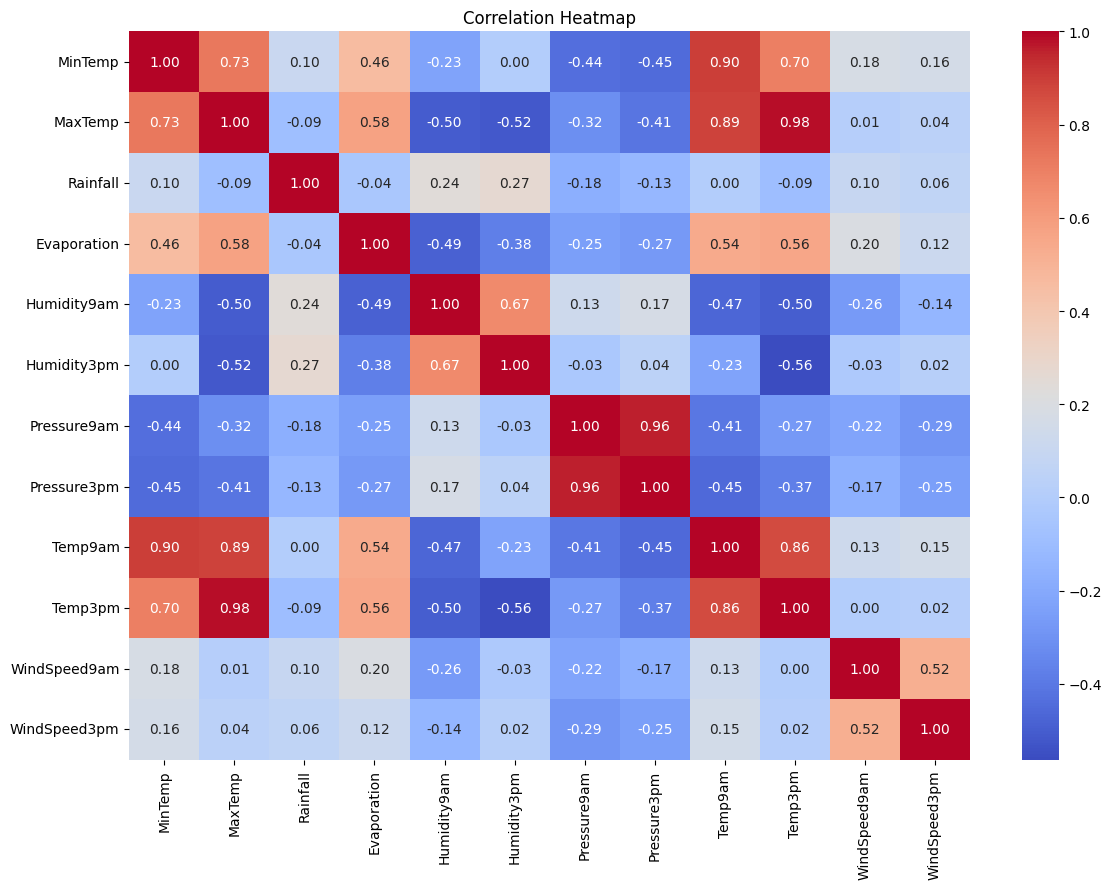

In [ ]:
sample = df.select("MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm", "Temp9am", "Temp3pm", "WindSpeed9am", "WindSpeed3pm").sample(False, 0.1, seed=42).toPandas()
plt.figure(figsize=(12, 9))
sns.heatmap(sample.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

La correlation heatmap permet de mieux comprendre les relations entre les différentes variables. Les valeurs représentées en rouge indiquent une corrélation positive (les variables évoluent dans le même sens), tandis que les valeurs en bleu indiquent une corrélation négative (les variables évoluent en sens inverse).

## Prétraitement

### Date processing (creating day-of-the-week feature)

In [ ]:
df = df.withColumn("Date", to_date(col("Date"), "yyyy-MM-dd"))
df = df.withColumn("Year", year(col("Date"))).withColumn("Month", month(col("Date"))).withColumn("Day", dayofmonth(col("Date"))).withColumn("DayOfWeek", dayofweek(col("Date"))).drop("Date")
df = df.withColumn("MonthSin", sin(2 * pi * col("Month") / 12)).withColumn("MonthCos", cos(2 * pi * col("Month") / 12))
df = df.withColumn("DayOfWeekSin", sin(2 * pi * col("DayOfWeek") / 7)).withColumn("DayOfWeekCos", cos(2 * pi * col("DayOfWeek") / 7))

temporal_features = ["MonthSin", "MonthCos", "DayOfWeekSin", "DayOfWeekCos"]

for c in temporal_features:
    if c not in numerical:
        numerical.append(c)
    

### Wind direction

In [ ]:
wind_directions = {
    "N": 0,
    "NNE": 22.5,
    "NE": 45,
    "ENE": 67.5,
    "E": 90,
    "ESE": 112.5,
    "SE": 135,
    "SSE": 157.5,
    "S": 180,
    "SSW": 202.5,
    "SW": 225,
    "WSW": 247.5,
    "W": 270,
    "WNW": 292.5,
    "NW": 315,
    "NNW": 337.5
}

wind_map = create_map(*[lit(x) for x in chain(*wind_directions.items())])
wind_columns = ["WindGustDir", "WindDir9am", "WindDir3pm"]

for c in wind_columns:
    df = df.withColumn(c, wind_map[col(c)])
    df = df.withColumn(c + "_sin", sin(radians(col(c)))).withColumn(c + "_cos", cos(radians(col(c))))
    df = df.drop(c)

    if c in categorical:
        categorical.remove(c)
    numerical.extend([c + "_sin", c + "_cos"])

### Removing null targets

In [113]:
df = df.filter(col("RainTomorrow").isNotNull())
print(f"Records after removing missing target: {df.count()}")

Records after removing missing target: 142193


### Handling missing categorical values

In [114]:
for c in categorical:
    df = df.withColumn(c, when(col(c).isNull(), lit("Missing")).otherwise(col(c)))

### Season feature

In [115]:
df = df.withColumn("Season", when(col("Month").isin(12, 1, 2), "Summer").when(col("Month").isin(3, 4, 5), "Autumn").when(col("Month").isin(6, 7, 8), "Winter").otherwise("Spring"))
categorical.append("Season")

## Data pipeline et Transformation

In [ ]:
# Numerical variables
imputed_cols = [c + "_imputed" for c in numerical]
imputer = Imputer(inputCols=numerical, outputCols=imputed_cols, strategy="median")
numerical_assembler = VectorAssembler(inputCols=imputed_cols, outputCol="numerical_features")
scaler = MinMaxScaler(inputCol="numerical_features", outputCol="scaled_numerical_features", min=0, max=1)

# Categorical variables
indexers = [StringIndexer(inputCol=c, outputCol=c + "_index", handleInvalid="keep") for c in categorical]
encoded_cols = [c + "_encoded" for c in categorical]
encoder = OneHotEncoder(inputCols=[c + "_index" for c in categorical], outputCols=encoded_cols)

label_indexer = StringIndexer(inputCol="RainTomorrow", outputCol="label", stringOrderType="alphabetAsc")
assemble = VectorAssembler(inputCols=["scaled_numerical_features"] + encoded_cols, outputCol="features")

pipeline = Pipeline(stages=[imputer, numerical_assembler, scaler, *indexers, encoder, label_indexer, assemble])

### Data separation

In [117]:
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)

print("Training counter:", train_df.count())
print("Testing counter:", test_df.count())

Training counter: 113916
Testing counter: 28277


### Adjusting dataset to machine learning data format

In [118]:
pipeline_model = pipeline.fit(train_df)
train_prepared = pipeline_model.transform(train_df)
test_prepared = pipeline_model.transform(test_df)

### New dataset visualization

In [119]:
train_prepared.select("features", "label").show(5, truncate=False)

+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|features                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

## Machine Learning

### Model training

In [ ]:
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=100, regParam=0.01, threshold=0.35)

model = lr.fit(train_prepared)

### Model test

In [121]:
predictions = model.transform(test_prepared)
predictions.select("label", "prediction", "probability").show(50, truncate=False)

+-----+----------+-----------------------------------------+
|label|prediction|probability                              |
+-----+----------+-----------------------------------------+
|0.0  |0.0       |[0.6751782308423095,0.32482176915769045] |
|0.0  |0.0       |[0.9572670833999745,0.04273291660002554] |
|1.0  |0.0       |[0.78590338465035,0.21409661534964997]   |
|0.0  |0.0       |[0.9701084086429319,0.029891591357068092]|
|0.0  |0.0       |[0.9870066519360106,0.01299334806398944] |
|0.0  |0.0       |[0.9618520174044716,0.03814798259552843] |
|0.0  |0.0       |[0.9833171731031636,0.016682826896836422]|
|0.0  |0.0       |[0.8559007053075851,0.1440992946924149]  |
|0.0  |0.0       |[0.949573367367762,0.05042663263223801]  |
|0.0  |0.0       |[0.9722934002649255,0.0277065997350745]  |
|0.0  |0.0       |[0.8991255337897399,0.10087446621026008] |
|0.0  |0.0       |[0.9845007369121697,0.01549926308783034] |
|0.0  |0.0       |[0.9272952909969954,0.07270470900300463] |
|0.0  |0.0       |[0.976

## Model evaluation

In [ ]:

accuracy = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy").evaluate(predictions)
metrics = MulticlassMetrics(predictions.select("prediction", "label").rdd)

precision_no = metrics.precision(0.0)
recall_no = metrics.recall(0.0)
f1_no = metrics.fMeasure(0.0)

precision_yes = metrics.precision(1.0)
recall_yes = metrics.recall(1.0)
f1_yes = metrics.fMeasure(1.0)

precision_weighted = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision").evaluate(predictions)
recall_weighted = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall").evaluate(predictions)
f1_weighted = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1").evaluate(predictions)

auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC").evaluate(predictions)

print(f"AUC-ROC: {auc:.4f}\nAccuracy: {accuracy:.4f}\n\n")
print(f"No Rain (0):\nPrecision: {precision_no:.4f}\nRecall: {recall_no:.4f}\nF1-score: {f1_no:.4f}\n\n")
print(f"Rain (1):\nPrecision: {precision_yes:.4f}\nRecall: {recall_yes:.4f}\nF1-score: {f1_yes:.4f}\n\n")
print(f"Weighted:\nPrecision: {precision_weighted:.4f}\nRecall: {recall_weighted:.4f}\nF1-score: {f1_weighted:.4f}")

/home/felipe/.local/lib/python3.10/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


AUC-ROC: 0.8643
Accuracy: 0.8325


No Rain (0):
Precision: 0.8950
Recall: 0.8885
F1-score: 0.8917


Rain (1):
Precision: 0.6228
Recall: 0.6385
F1-score: 0.6306


Weighted:
Precision: 0.8341
Recall: 0.8325
F1-score: 0.8333


### ROC AUC curve

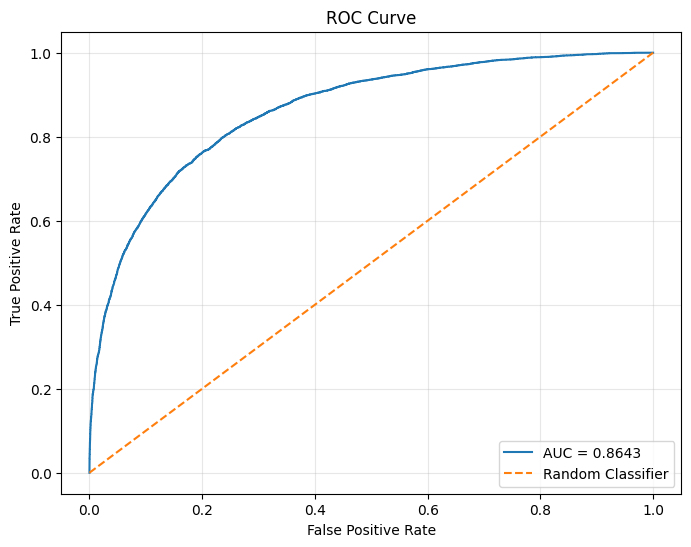

In [123]:
results = predictions.select("label", "probability").toPandas()
fpr, tpr, thresholds = roc_curve(results["label"], results["probability"].apply(lambda x: float(x[1])))

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### Confunsion matrix

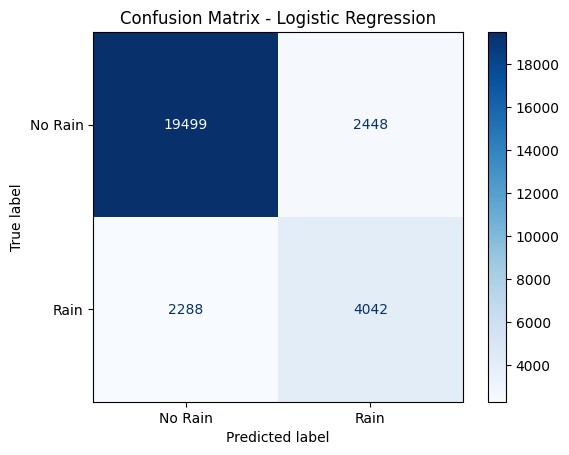

In [124]:
results = predictions.select("label", "prediction").toPandas()
y_true = results["label"]
y_pred = results["prediction"]

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Rain", "Rain"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

Avec un F1-score pondéré de 0,8333 et une AUC-ROC de 0,8643, toutes les métriques étant supérieures à 0,5 (ce qui indique que le modèle réalise davantage de prédictions correctes qu'incorrectes), ainsi qu'une accuracy de 0,8325, supérieure à celle obtenue par un modèle qui prédirait systématiquement la classe majoritaire (« No Rain »), soit 0,7761, on peut conclure que le modèle proposé présente de bonnes performances sur le jeu de données étudié.